In [1]:
#Imports ?
import numpy as np
import pandas as pd
import xarray as xr

import geopandas as gpd

from netCDF4 import Dataset

import matplotlib.pyplot as plt
#from mpl_toolkits.basemap import Basemap

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point

from scipy import stats
from scipy import ndimage
from scipy.stats import rankdata

**Calculate seasonal anomalies of precip**

In [2]:
precip= xr.open_dataset('../../Data-Other/CDR_Global_198301_202508.nc', engine='netcdf4')
#precip = precip.sel(datetime=slice('1991-01-01', '2024-12-01'))
precip = precip.sel(lat=slice(40, 20))
precip = precip.sel(lon=slice(-20, 0))
precip

<xarray.Dataset> Size: 13MB
Dimensions:   (datetime: 512, lat: 81, lon: 81)
Coordinates:
  * datetime  (datetime) datetime64[ns] 4kB 1983-01-01 1983-02-01 ... 2025-08-01
  * lat       (lat) float32 324B 40.0 39.75 39.5 39.25 ... 20.75 20.5 20.25 20.0
  * lon       (lon) float32 324B -20.0 -19.75 -19.5 -19.25 ... -0.5 -0.25 0.0
Data variables:
    crs       int32 4B ...
    precip    (datetime, lat, lon) float32 13MB ...
Attributes:
    Conventions:  CF-1.6

In [3]:
#Code ?
# 1. Create date coordinate efficiently without making a copy of the dataset 
precip.coords['date'] = pd.to_datetime(precip['datetime'].values.astype(str)) 
# 2. Extract relevant variables directly to reduce memory load 
df = precip['precip'].to_dataframe().dropna().reset_index() 
# # 3. Extract year and month efficiently 
df['year'] = df['datetime'].dt.year 
df['month'] = df['datetime'].dt.month 
# **FAST NumPy Vectorized Method for Assigning Seasons** 
seasons = np.array(["DJF", "MAM", "JJA", "SON"]) 
# Define conditions for season assignment 
winter = df['month'].isin([12, 1, 2]) 
spring = df['month'].isin([3, 4, 5]) 
summer = df['month'].isin([6, 7, 8]) 
autumn = df['month'].isin([9, 10, 11]) 
# Assign seasons using np.select (much faster than apply) 
df['season'] = np.select([winter, spring, summer, autumn], seasons, default=None) 
# 5. Adjust season_year directly 
df['season_year'] = df['year'].values 
df.loc[df['month'] == 12, 'season_year'] += 1

In [4]:
df

,datetime,lat,lon,precip,year,month,season,season_year
0,1983-01-01,40.0,-20.00,78.622032,1983,1,DJF,1983
1,1983-01-01,40.0,-19.75,87.029778,1983,1,DJF,1983
2,1983-01-01,40.0,-19.50,88.797325,1983,1,DJF,1983
3,1983-01-01,40.0,-19.25,78.830261,1983,1,DJF,1983
4,1983-01-01,40.0,-19.00,85.789146,1983,1,DJF,1983
...,...,...,...,...,...,...,...,...
3359227,2025-08-01,20.0,-1.00,32.236622,2025,8,JJA,2025
3359228,2025-08-01,20.0,-0.75,46.327202,2025,8,JJA,2025
3359229,2025-08-01,20.0,-0.50,46.308113,2025,8,JJA,2025
3359230,2025-08-01,20.0,-0.25,44.589256,2025,8,JJA,2025


In [5]:
df = precip['precip'].to_dataframe().reset_index()
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month

# Subset only reference period
climatology_base = df[(df['year'] >= 1991) & (df['year'] <= 2020)]

# Monthly climatological mean for each grid point (lat/lon)
monthly_clim_mean = (
    climatology_base
    .groupby(['month', 'lat', 'lon'])['precip']
    .mean()
    .rename('clim')
    .reset_index()
)

# Calculate anomalies: (P - clim) / clim * 100
df_anom = df.merge(monthly_clim_mean, on=['month', 'lat', 'lon'], how='left')
#df_anom['precip_anom_pct'] = df_anom['precip'] - df_anom['clim'] #for the absolute anomaly to do Pearson correlation plot, use this line instead of the one below

df_anom['precip_anom_pct'] = (df_anom['precip'] - df_anom['clim']) / df_anom['clim'].std() #for the Standardized anomaly using std_dev to plot precipitation TS
#df_anom['precip_anom_pct'] = np.log(df_anom['precip'] / df_anom['clim']) #for the Log ratio to plot precipitation TS
#df_anom['precip_anom_pct'] = ((df_anom['precip'] - df_anom['clim']) / df_anom['clim']) * 100 #for the percentage anomaly to plot precipitation TS

# Assign seasons
winter = df_anom['month'].isin([12, 1, 2])
spring = df_anom['month'].isin([3, 4, 5])
summer = df_anom['month'].isin([6, 7, 8])
autumn = df_anom['month'].isin([9, 10, 11])
df_anom['season'] = np.select([winter, spring, summer, autumn], seasons, default=None)

# Season-year (shift December to next year)
df_anom['season_year'] = df_anom['year']
df_anom.loc[df_anom['month'] == 12, 'season_year'] += 1

# Seasonal anomalies (rows: season_year/season, columns: grid points)
seasonal_anom = (
    df_anom
    .groupby(['season_year', 'season', 'lat', 'lon'])['precip_anom_pct']
    .mean()
    .unstack(['lat', 'lon'])
    .sort_index()
)

# Annual anomalies (rows: year, columns: grid points)
annual_anom = (
    df_anom
    .groupby(['year', 'lat', 'lon'])['precip_anom_pct']
    .mean()
    .unstack(['lat', 'lon'])
    .sort_index()
)

seasonal_anom

lat                     20.0                                          \
lon                   -20.00    -19.75    -19.50    -19.25    -19.00   
season_year season                                                     
1983        DJF     0.764633  0.812149  0.907143  0.977011  0.961183   
            JJA     0.235601  0.203800  0.309344  0.252807  0.223656   
            MAM     1.475014  1.308643  1.356939  1.139151  1.188683   
            SON     0.204369  0.073840  0.045147  0.126505  0.123953   
1984        DJF     0.420419  0.478648  0.643583  0.574264  0.625275   
...                      ...       ...       ...       ...       ...   
2024        MAM    -0.052670 -0.066097 -0.053378 -0.065879 -0.063039   
            SON    -0.376316 -0.319002 -0.321544 -0.277380 -0.265343   
2025        DJF    -0.260588 -0.259926 -0.252591 -0.241926 -0.238352   
            JJA    -0.008817 -0.030831 -0.054134 -0.078595 -0.068087   
            MAM     0.370474  0.240087  0.213646  0.104813  0.100655   

lat                                                                   ...  \
lon                   -18.75    -18.50    -18.25    -18.00    -17.75  ...   
season_year season                                                    ...   
1983        DJF     0.793625  0.696167  0.613015  0.499669  0.349028  ...   
            JJA     0.144423  0.232172  0.238466  0.121110  0.066556  ...   
            MAM     1.147180  1.207513  0.920681  0.940863  0.728917  ...   
            SON     0.114300  0.122158  0.029678  0.084702  0.010580  ...   
1984        DJF     0.526964  0.482886  0.477849  0.456492  0.259385  ...   
...                      ...       ...       ...       ...       ...  ...   
2024        MAM    -0.068355 -0.073668 -0.027069 -0.021449 -0.029219  ...   
            SON    -0.247333 -0.231293 -0.202885 -0.177698 -0.156301  ...   
2025        DJF    -0.205340 -0.181343 -0.161151 -0.141988 -0.119237  ...   
            JJA    -0.061597 -0.060526 -0.065900 -0.106088 -0.082272  ...   
            MAM     0.099757  0.120516  0.092914  0.116901  0.098693  ...   

lat                     40.0                                          \
lon                   -2.25     -2.00     -1.75     -1.50     -1.25    
season_year season                                                     
1983        DJF    -1.072317 -0.976494 -1.027370 -1.037302 -1.116103   
            JJA     0.887876  0.904573  0.991337  1.045026  0.808993   
            MAM    -1.373165 -1.424569 -1.450946 -1.517261 -1.641465   
            SON    -0.653254 -0.684538 -0.754921 -0.710502 -0.637332   
1984        DJF    -2.389459 -2.381422 -2.414767 -2.488375 -2.685988   
...                      ...       ...       ...       ...       ...   
2024        MAM    -0.348862 -0.456142 -0.519249 -0.621842 -0.696889   
            SON     0.113998  0.474641  0.530139  0.845349  1.040513   
2025        DJF    -0.750811 -0.778221 -0.870008 -0.932470 -0.894084   
            JJA    -0.192247  0.014089  0.113122  0.011092  0.001719   
            MAM     1.307692  1.180966  0.858094  0.996181  1.015974   

lat                                                                   
lon                   -1.00     -0.75     -0.50     -0.25      0.00   
season_year season                                                    
1983        DJF    -1.235801 -1.647530 -1.892011 -2.136174 -2.127998  
            JJA     0.759669  0.645613  0.641013  0.726722  0.965407  
            MAM    -1.661103 -1.741209 -1.895846 -1.810370 -1.705731  
            SON    -0.808981 -0.532609 -0.256959 -0.234280 -0.297588  
1984        DJF    -2.821012 -3.016951 -3.152961 -3.233140 -3.237055  
...                      ...       ...       ...       ...       ...  
2024        MAM    -0.782110 -0.709203 -0.714260 -0.915561 -0.505098  
            SON     1.098429  1.099995  1.087777  1.338853  1.346078  
2025        DJF    -0.809234 -0.789959 -0.828537 -0.780285 -0.927715  
            JJA     0.066766  0.029495  0.034719 -0

**Lagged and concurrent SST-precipitation correlation (global SST vs Morocco DJF precipitation anomaly, 1991-2023)**

In [6]:
# --- Load SST data and Morocco shapefile ---
sst_anom = xr.open_dataset('../../Data-Other/Article3_data/sst_seasonal_anomalies.nc', engine='netcdf4')
morocco_shp = "/Users/workad/Workspace/Data-Other/shapfiles/Morocco/Morocco.shp"

# 1) Build Morocco-mean DJF precipitation anomaly time series from gridded seasonal_anom (Cell 6)
djf_grid = seasonal_anom.xs('DJF', level='season').copy()

# Convert DataFrame (rows=season_year, cols=(lat, lon)) to xarray DataArray
djf_long = djf_grid.stack([0, 1]).rename('precip_anom').reset_index()
djf_long.columns = ['season_year', 'lat', 'lon', 'precip_anom']
djf_xr = djf_long.set_index(['season_year', 'lat', 'lon']).to_xarray()['precip_anom']

# Read Morocco polygon and enforce lon/lat CRS
morocco = gpd.read_file(morocco_shp)
if morocco.crs is None:
    morocco = morocco.set_crs('EPSG:4326')
else:
    morocco = morocco.to_crs('EPSG:4326')
morocco_geom = morocco.union_all()

# Build gridpoint mask for Morocco
lats_p = djf_xr['lat'].values
lons_p = djf_xr['lon'].values
lon2d_p, lat2d_p = np.meshgrid(lons_p, lats_p)
pts = gpd.GeoSeries(gpd.points_from_xy(lon2d_p.ravel(), lat2d_p.ravel()), crs='EPSG:4326')
inside = (pts.within(morocco_geom) | pts.touches(morocco_geom)).to_numpy().reshape(lat2d_p.shape)

if not inside.any():
    raise ValueError('No precipitation grid points found inside Morocco. Check shapefile CRS and grid extent.')

mask_p = xr.DataArray(inside, coords={'lat': lats_p, 'lon': lons_p}, dims=('lat', 'lon'))

# Area weighting (cos(lat)) for spatial mean over Morocco points only
lat_w = np.cos(np.deg2rad(lats_p))
w2d = np.repeat(lat_w[:, None], len(lons_p), axis=1)
w2d = np.where(inside, w2d, 0.0)
w_da = xr.DataArray(w2d, coords={'lat': lats_p, 'lon': lons_p}, dims=('lat', 'lon'))

precip_djf_ts = (
    djf_xr.where(mask_p)
    .weighted(w_da)
    .mean(dim=('lat', 'lon'))
    .to_series()
    .dropna()
    .sort_index()
)
precip_djf_ts.index = precip_djf_ts.index.astype(int)
precip_djf_ts = precip_djf_ts.loc[1991:2024]#.dropna()

# If you want SPEI12 instead, compute Morocco-mean DJF SPEI12 similarly and assign to precip_djf_ts.
# spei_djf_ts = seasonal_mean.xs('DJF', level='season').mean(axis=1)
# spei_djf_ts.index = spei_djf_ts.index.astype(int)
# precip_djf_ts = spei_djf_ts.loc[1991:2024].dropna()

# 2) Get SST variable
sst_var_name = list(sst_anom.data_vars)[0]
sst = sst_anom[sst_var_name]

lat_name = 'lat' if 'lat' in sst.coords else 'latitude'
lon_name = 'lon' if 'lon' in sst.coords else 'longitude'

def _to_numpy_text(series_like):
    """Force pandas/pyarrow string data to a plain NumPy array for xarray coords."""
    s = pd.Series(series_like).astype('string').astype(str)
    return np.asarray(s.to_numpy(), dtype=object)

def prepare_sst_season_year(da):
    """Return DataArray with coordinates season (SON/DJF/...) and season_year as integers."""
    season_map = {
        'son': 'SON', 'autumn': 'SON', 'fall': 'SON',
        'djf': 'DJF', 'winter': 'DJF',
        'mam': 'MAM', 'spring': 'MAM',
        'jja': 'JJA', 'summer': 'JJA',
    }

    # Case A: date labels like 'Autumn 2020' or 'Winter 2021'
    if 'date' in da.coords:
        labels = pd.Index(da['date'].values.astype(str)).str.strip()
        parsed = labels.str.extract(r'^(?P<season>[A-Za-z]+)\s+(?P<year>\d{4})$')
        if parsed.isna().any().any():
            bad = labels[parsed.isna().any(axis=1)].tolist()[:5]
            raise ValueError(f"Could not parse some SST date labels (examples): {bad}")

        season_std = parsed['season'].str.lower().map(season_map)
        if season_std.isna().any():
            bad = parsed.loc[season_std.isna(), 'season'].unique().tolist()
            raise ValueError(f"Unrecognized SST season labels: {bad}")

        season_np = _to_numpy_text(season_std)
        year_np = parsed['year'].astype(int).to_numpy()
        out = da.assign_coords(
            season=('date', season_np),
            season_year=('date', year_np),
        )
        return out

    # Case B: explicit season + year/season_year coords already exist
    if 'season' in da.coords and ('season_year' in da.coords or 'year' in da.coords):
        if 'season_year' not in da.coords:
            da = da.assign_coords(season_year=da['year'])
        season_raw = pd.Series(da['season'].values.astype(str))
        season_std = season_raw.str.lower().map(season_map)
        if season_std.isna().any():
            bad = season_raw[season_std.isna()].unique().tolist()
            raise ValueError(f"Unrecognized SST season labels: {bad}")
        season_np = _to_numpy_text(season_std)
        season_dims = da['season'].dims
        out = da.assign_coords(season=(season_dims, season_np))
        return out

    raise ValueError("SST data must have either a 'date' coordinate or explicit 'season' + 'year/season_year'.")

sst_prepped = prepare_sst_season_year(sst)

# 3) Build SON and DJF SST fields with season_year dimension
if 'date' in sst_prepped.dims:
    son = sst_prepped.where(sst_prepped['season'] == 'SON', drop=True)
    djf = sst_prepped.where(sst_prepped['season'] == 'DJF', drop=True)
    son = son.assign_coords(season_year=('date', son['season_year'].values)).swap_dims({'date': 'season_year'}).drop_vars('date')
    djf = djf.assign_coords(season_year=('date', djf['season_year'].values)).swap_dims({'date': 'season_year'}).drop_vars('date')
else:
    son = sst_prepped.sel(season='SON')
    djf = sst_prepped.sel(season='DJF')
    if 'year' in son.dims:
        son = son.rename({'year': 'season_year'})
    if 'year' in djf.dims:
        djf = djf.rename({'year': 'season_year'})

# 4) Lag alignment: SON(Y) -> DJF(Y+1)
son = son.assign_coords(season_year=son['season_year'] + 1)

# 5) Align years with target series (1991-2024)
son_years = np.array(son['season_year'].values).astype(int)
djf_years = np.array(djf['season_year'].values).astype(int)
target_years = precip_djf_ts.index.values.astype(int)

common_lag = np.intersect1d(son_years, target_years)
common_conc = np.intersect1d(djf_years, target_years)

son_aligned = son.sel(season_year=common_lag).sortby('season_year')
djf_aligned = djf.sel(season_year=common_conc).sortby('season_year')
y_lag = precip_djf_ts.loc[common_lag].values
y_conc = precip_djf_ts.loc[common_conc].values

y_lag_da = xr.DataArray(y_lag, dims=['season_year'], coords={'season_year': common_lag})
y_conc_da = xr.DataArray(y_conc, dims=['season_year'], coords={'season_year': common_conc})

# 6) Gridpoint correlation + pointwise significance (two-tailed t-test)
def corr_and_pvalue(sst_field, target_da):
    r = xr.corr(sst_field, target_da, dim='season_year')
    valid_n = xr.where(np.isfinite(sst_field) & np.isfinite(target_da), 1, 0).sum(dim='season_year')
    r_clip = xr.where(np.isfinite(r), np.clip(r, -0.999999, 0.999999), np.nan)
    tval = r_clip * np.sqrt((valid_n - 2) / (1 - r_clip**2))
    pval = xr.apply_ufunc(
        lambda t, df: 2 * stats.t.sf(np.abs(t), df),
        tval,
        valid_n - 2,
        vectorize=True,
        dask='allowed',
    )
    return r, pval

# Before calling the function, ensure sst_field is a DataArray:
print(type(son_aligned))  # Should be <class 'xarray.core.dataarray.DataArray'>
print(type(y_lag_da))      # Should be <class 'xarray.core.dataarray.DataArray'>

r_lag, p_lag = corr_and_pvalue(son_aligned, y_lag_da)
r_conc, p_conc = corr_and_pvalue(djf_aligned, y_conc_da)

# 7) Plotting helpers
def add_cyclic(da):
    vals, cyc_lon = add_cyclic_point(da.values, coord=da[lon_name].values)
    lats = da[lat_name].values
    return vals, cyc_lon, lats

r_lag_c, lon_c, lat_vals = add_cyclic(r_lag)
r_conc_c, _, _ = add_cyclic(r_conc)
sig_lag_c, _, _ = add_cyclic((p_lag < 0.05).astype(int))
sig_conc_c, _, _ = add_cyclic((p_conc < 0.05).astype(int))

<class 'xarray.core.dataarray.DataArray'>
<class 'xarray.core.dataarray.DataArray'>


/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


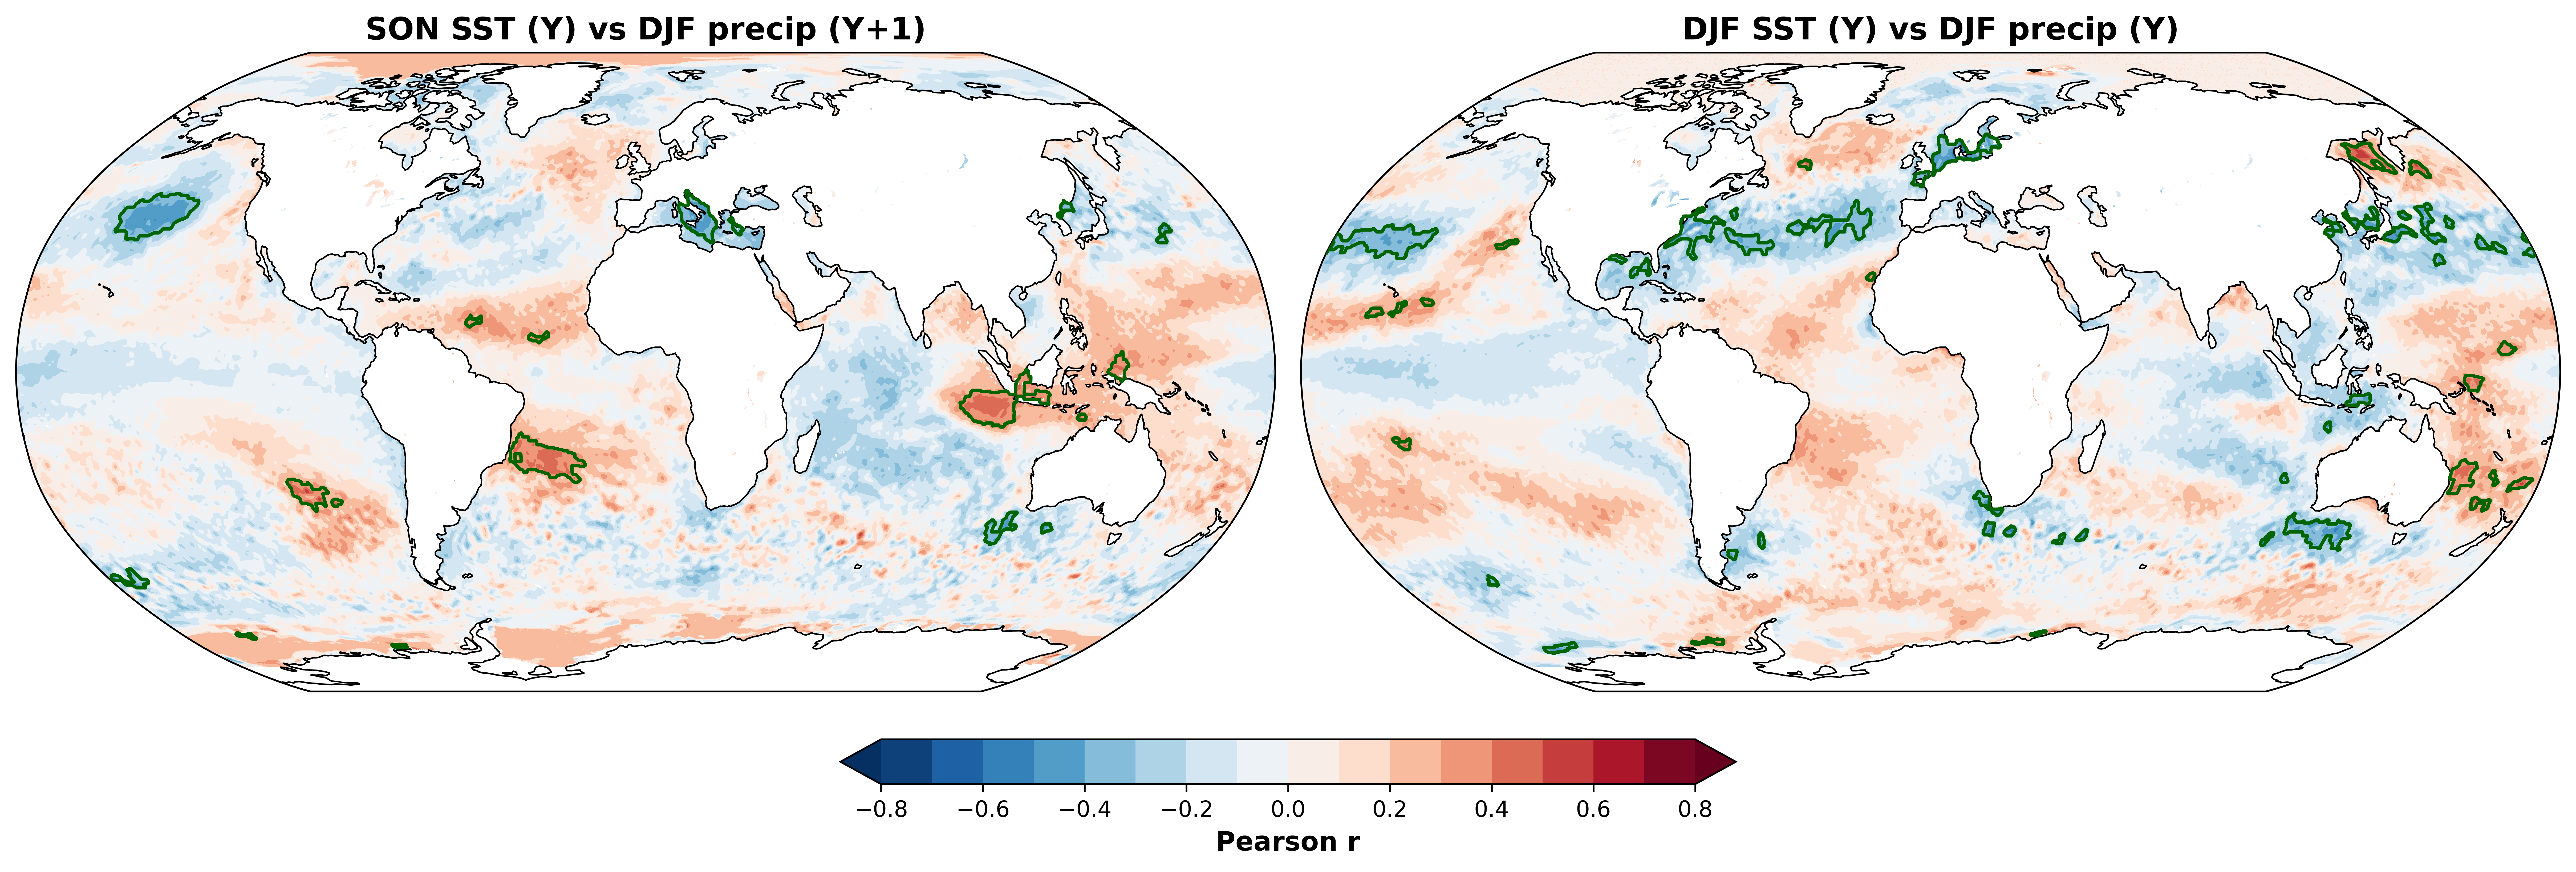

In [8]:
# 8) Plot two-panel comparison
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
proj = ccrs.Robinson()
pc = ccrs.PlateCarree()
levels = np.linspace(-0.8, 0.8, 17)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 5.8), subplot_kw={'projection': proj}, constrained_layout=True
)

panel_data = [
    (r_lag_c, sig_lag_c, 'SON SST (Y) vs DJF precip (Y+1)'),
    (r_conc_c, sig_conc_c, 'DJF SST (Y) vs DJF precip (Y)'),
]

for ax, (rmap, sigmap, title) in zip(axes, panel_data):
    cf = ax.contourf(
        lon_c, lat_vals, rmap,
        levels=levels, cmap='RdBu_r', extend='both',
        transform=pc
    )

    # Build a cleaner significance mask for contouring/hatching
    sig_binary = sigmap.astype(bool)
    structure = ndimage.generate_binary_structure(2, 2)
    labeled, num_features = ndimage.label(sig_binary, structure=structure)

    min_pixels = 50
    sig_clean = np.zeros_like(sig_binary, dtype=bool)
    for region_id in range(1, num_features + 1):
        region = labeled == region_id
        if region.sum() >= min_pixels:
            sig_clean |= region

    sig_closed = ndimage.binary_closing(sig_clean, structure=structure, iterations=3)

    # Use the cyclic longitude array here as well, since sigmap already includes the cyclic column
    ax.contour(
        lon_c, lat_vals, sig_closed.astype(float),
        levels=[0.5], colors='darkgreen', linewidths=1.5,
        transform=pc, zorder=3
    )
    #ax.contourf(
    #    lon_c, lat_vals, sigmap,
    #    levels=[0.5, 1.5],
    #    hatches=['....'], colors='none',
    #    transform=pc
    #)
    ax.coastlines(resolution='110m', linewidth=0.7)
    ax.add_feature(cfeature.LAND, facecolor='white', linewidth=0.25)
    ax.set_title(title, fontsize=14, fontweight='bold')

cbar = fig.colorbar(cf, ax=axes, orientation='horizontal', pad=0.06, fraction=0.06)
cbar.set_label('Pearson r', fontsize=12, fontweight='bold')

# --- EXPORT / DISPLAY ---
plt.savefig("LaggedPearsonCorrelation.png", dpi=600)
plt.show()

**Plotting the time-series of precipitation anomalies (annual and seasonal)**

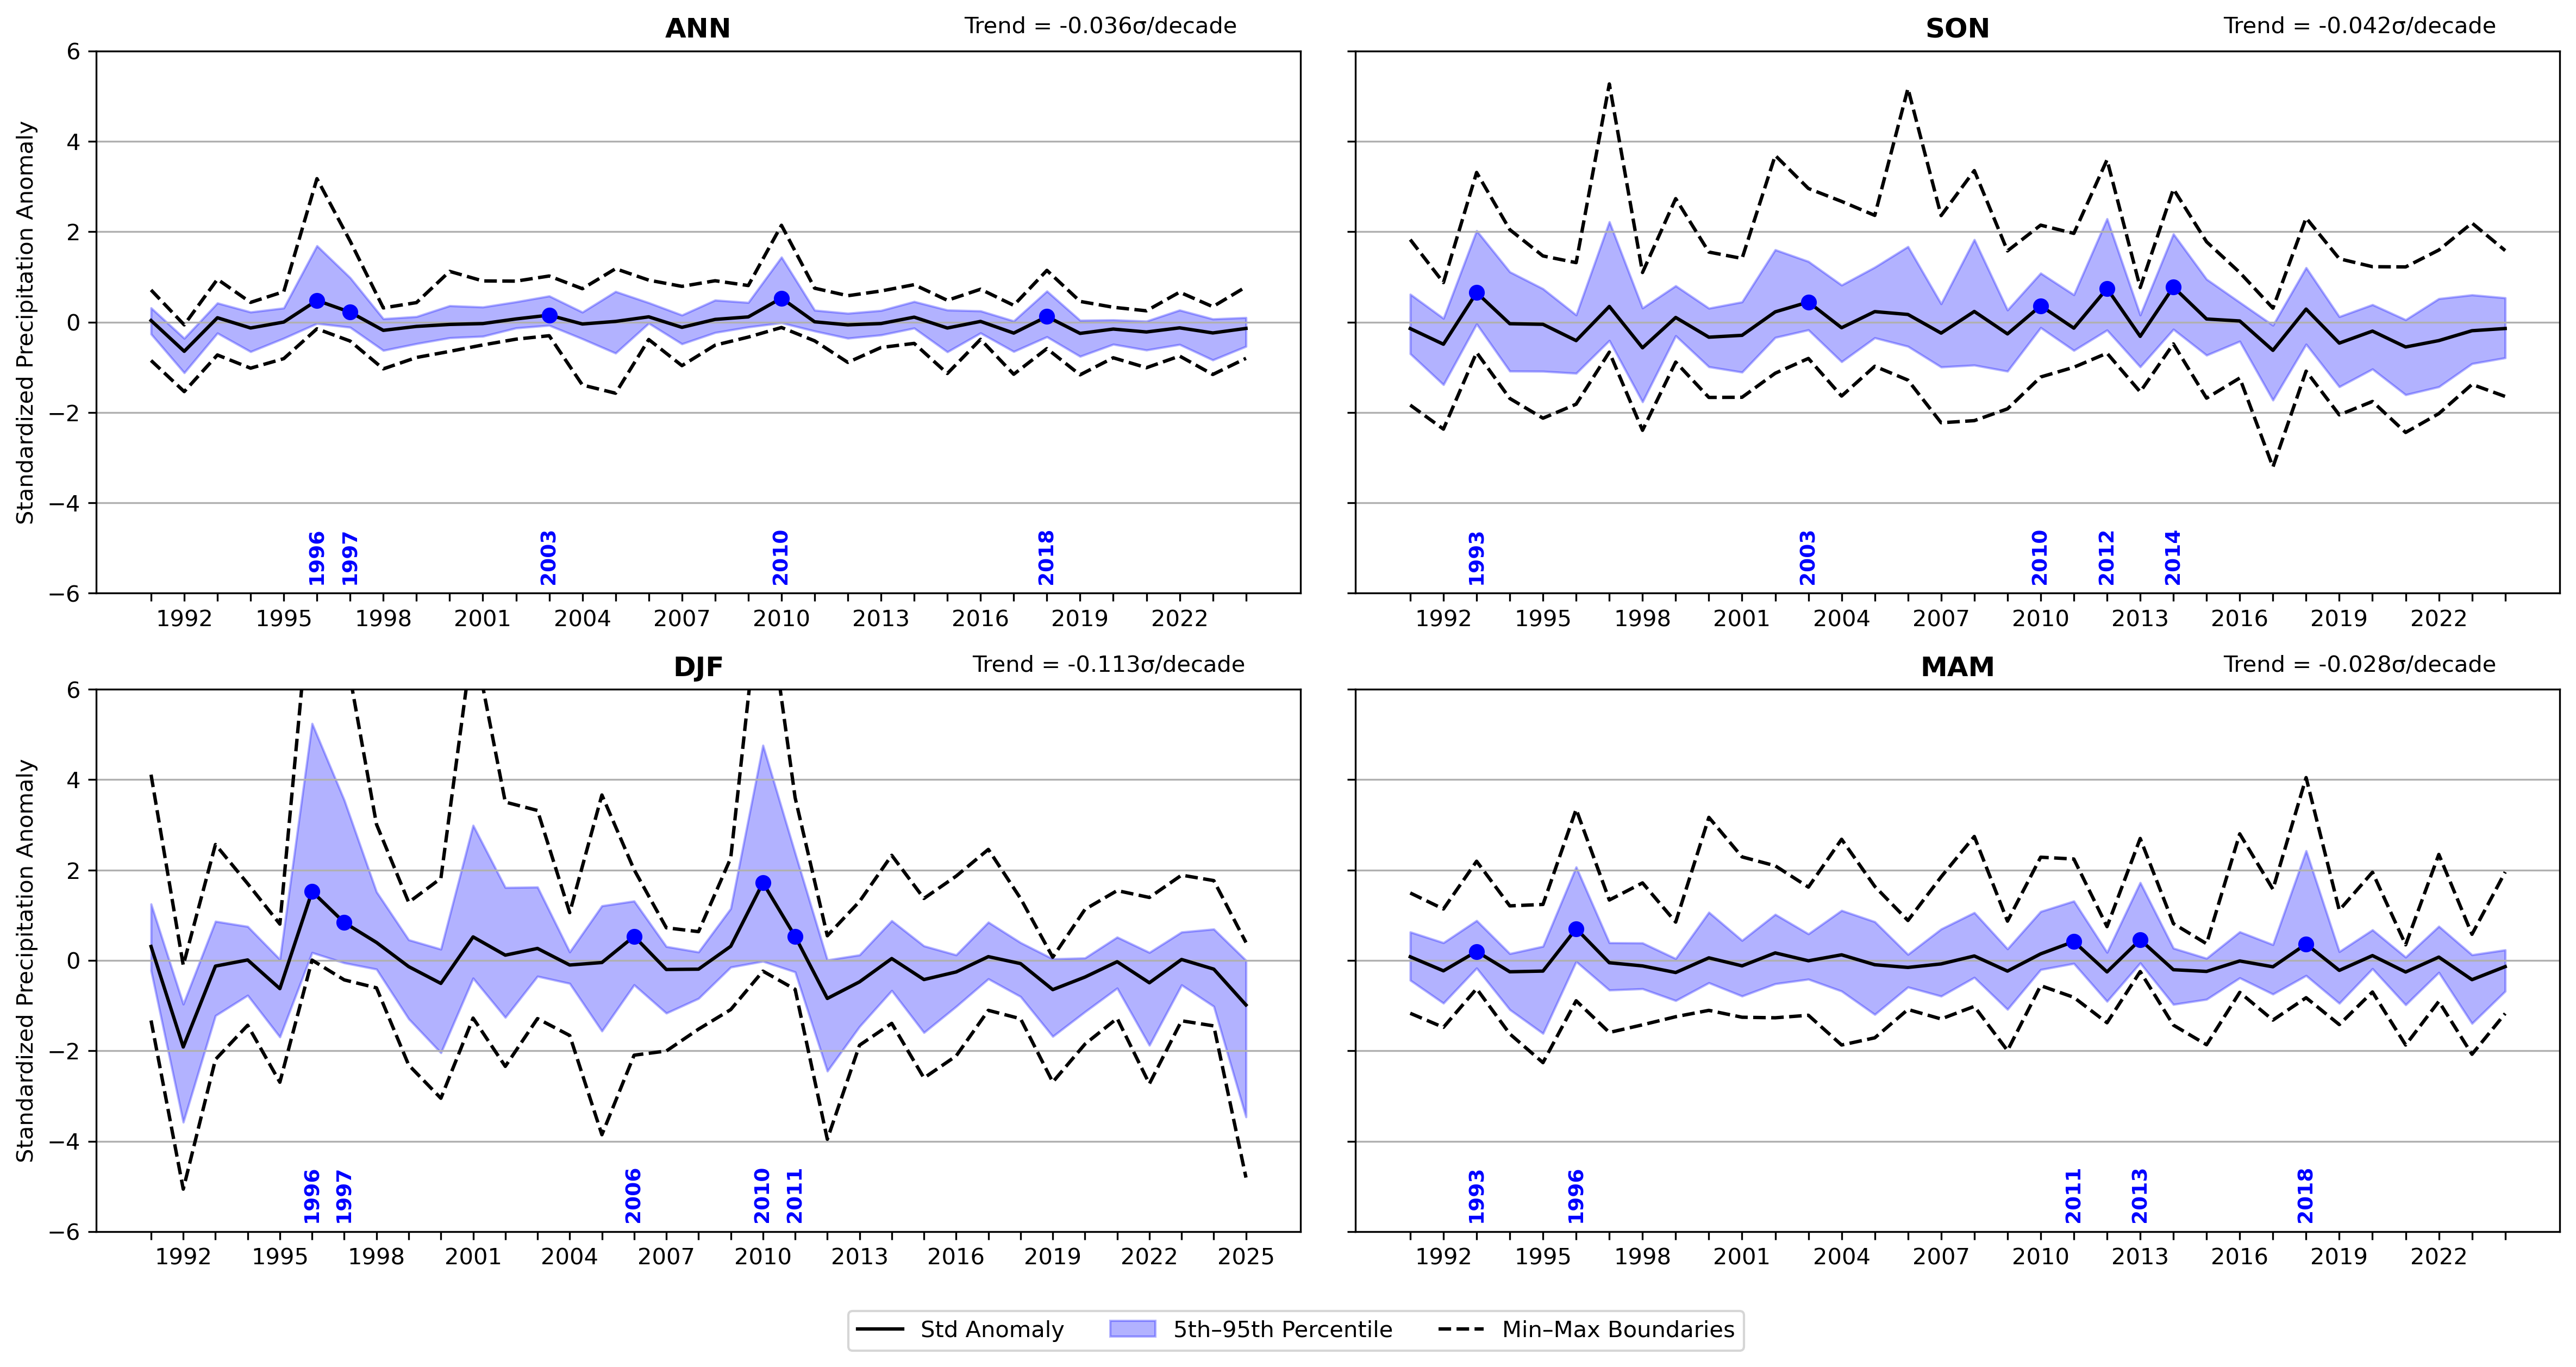

In [67]:
import matplotlib.pyplot as plt 
import numpy as np 
from scipy.stats import linregress 

# Subset the required seasons 
son_df = seasonal_anom.xs('SON', level='season') 
djf_df = seasonal_anom.xs('DJF', level='season') 
mam_df = seasonal_anom.xs('MAM', level='season') 
# Function to calculate summary stats for plotting
def compute_stats(df):
    df_stats = pd.DataFrame({
        'mean': df.mean(axis=1),
        'p5': df.quantile(0.05, axis=1),
        'p95': df.quantile(0.95, axis=1),
        'min': df.min(axis=1),
        'max': df.max(axis=1)
    })
    df_stats.index.name = 'season_year'
    df_stats.reset_index(inplace=True)
    return df_stats
# Compute stats for each season
ann_stats = compute_stats(annual_anom)
son_stats = compute_stats(son_df)
djf_stats = compute_stats(djf_df)
mam_stats = compute_stats(mam_df)
# List of all stats and labels
panels = [('ANN', ann_stats), ('SON', son_stats), ('DJF', djf_stats), ('MAM', mam_stats)]
# === PLOT ===
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharey=True)
axes = axes.flatten()
for i, (title, stats) in enumerate(panels):
    ax = axes[i]
    # Plot mean line
    ax.plot(stats['season_year'], stats['mean'], color='black', label='Std Anomaly')
    ax.fill_between(stats['season_year'], stats['p5'], stats['p95'], color='blue', alpha=0.3, label='5th–95th Percentile')
    ax.plot(stats['season_year'], stats['min'], linestyle='--', color='black', label='Min–Max Boundaries' if i == 0 else "")
    ax.plot(stats['season_year'], stats['max'], linestyle='--', color='black')
    # Trend line calculation
    x = stats['season_year'].values
    y = stats['mean'].values
    slope, intercept, *_ = linregress(x, y)
    trend_per_decade = slope * 10
    ax.text(x.max() - 8.5, 6.4, f"Trend = {trend_per_decade:.3f}σ/decade", fontsize=10, color='black')
    # X-axis ticks: marks every year, label every 3 years
    years = np.arange(x.min(), x.max() + 1)
    year_labels = [str(y) if y % 3 == 0 else "" for y in years]
    ax.set_xticks(years)
    ax.set_xticklabels(year_labels, rotation=0)
    # Highlight 5 driest years
    #lowest = stats.nsmallest(5, 'mean')
    #ax.scatter(lowest['season_year'], lowest['mean'], color='red', zorder=5)
    #for _, row in lowest.iterrows():
    #    ax.text(row['season_year'], row['mean'] - 3, str(int(row['season_year'])), color='red', fontsize=9, ha='center', rotation=90)
    # Highlight 5 driest years
    highest = stats.nlargest(5, 'mean')
    ax.scatter(highest['season_year'], highest['mean'], color='blue', zorder=5)
    for _, row in highest.iterrows():
        ax.text(row['season_year'], -5.7, str(int(row['season_year'])), color='blue', fontsize=9, ha='center', rotation=90, fontdict={'weight':'bold'})
    
    # Highlight anomalies >= 80mm
    #clip_val = 6  # visible y-axis threshold
    # Identify years where the true max exceeds the visual cap
    #outliers = stats[stats['max'] > clip_val]
    # Annotate the actual value just above the triangle
    #for _, row in outliers.iterrows():
    #    ax.text(row['season_year'], clip_val + 4, f"{row['max']:.0f}", color='black', fontsize=8, ha='center', va='bottom', rotation=90)
    ax.set_title(title, fontdict={'weight':'bold'})
    if i % 2 == 0:
        ax.set_ylabel("Standardized Precipitation Anomaly")
    ax.grid(axis='y')
    # Visually cap the y-axis range
    ax.set_ylim(-5, 5)
# Add legend only once
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.subplots_adjust(bottom=0.05)
plt.show()

**SPEI12 plots**

In [ ]:
import pandas as pd
import numpy as np

# Ensure datetime index
spei_df.index = pd.to_datetime(spei_df.index)

# Step 1: Extract year and month
df = spei_df.copy()
df['year'] = df.index.year
df['month'] = df.index.month

# Step 2: Assign seasons
seasons = np.array(["DJF", "MAM", "JJA", "SON"])
winter = df['month'].isin([12, 1, 2])
spring = df['month'].isin([3, 4, 5])
summer = df['month'].isin([6, 7, 8])
autumn = df['month'].isin([9, 10, 11])

df['season'] = np.select([winter, spring, summer, autumn], seasons, default=None)

# Step 3: Adjust season_year for DJF (shift December to next year)
df['season_year'] = df['year']
df.loc[df['month'] == 12, 'season_year'] += 1

# Step 4: Drop month/year for aggregation
df.drop(columns=['month', 'year'], inplace=True)

# Step 5: Group by season and season_year and compute seasonal mean
seasonal_mean = df.groupby(['season_year', 'season']).mean().sort_index()

In [ ]:
# Replace -inf and inf with NaN
spei_clean = spei_df.replace([np.inf, -np.inf], np.nan)
spei_clean['year'] = spei_clean.index.year
annual_mean = spei_clean.groupby('year').mean()

# Compute summary stats
ann_stats = pd.DataFrame({
    'season_year': annual_mean.index,
    'mean': annual_mean.mean(axis=1),
    'p5': annual_mean.quantile(0.05, axis=1),
    'p95': annual_mean.quantile(0.95, axis=1),
    'min': annual_mean.min(axis=1),
    'max': annual_mean.max(axis=1)
})

In [ ]:
import matplotlib.pyplot as plt 
import numpy as np 
from scipy.stats import linregress 

# Subset the required seasons 
son_df = seasonal_mean.xs('SON', level='season') 
djf_df = seasonal_mean.xs('DJF', level='season') 
mam_df = seasonal_mean.xs('MAM', level='season') 
# Function to calculate summary stats for plotting
def compute_stats(df):
    df_stats = pd.DataFrame({
        'mean': df.mean(axis=1),
        'p5': df.quantile(0.05, axis=1),
        'p95': df.quantile(0.95, axis=1),
        'min': df.min(axis=1),
        'max': df.max(axis=1)
    })
    df_stats.index.name = 'season_year'
    df_stats.reset_index(inplace=True)
    return df_stats

# Compute stats for each season
ann_stats = compute_stats(annual_mean)
son_stats = compute_stats(son_df)
djf_stats = compute_stats(djf_df)
mam_stats = compute_stats(mam_df)

# List of all stats and labels
panels = [('ANN', ann_stats), ('SON', son_stats), ('DJF', djf_stats), ('MAM', mam_stats)]

# === PLOT ===
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharey=True)
axes = axes.flatten()

for i, (title, stats) in enumerate(panels):
    ax = axes[i]
    # Plot mean line
    ax.plot(stats['season_year'], stats['mean'], color='black', label='Mean SPEI')
    ax.fill_between(stats['season_year'], stats['p5'], stats['p95'], color='orange', alpha=0.3, label='5th–95th Percentile')
    ax.plot(stats['season_year'], stats['min'], linestyle='--', color='black', label='Min–Max Boundaries' if i == 0 else "")
    ax.plot(stats['season_year'], stats['max'], linestyle='--', color='black')

     # === Trend line calculation ===
    x = stats['season_year'].values
    y = stats['mean'].values
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    trend_per_decade = slope * 10

    # Plot the trend line
    ax.plot(x, intercept + slope * x, color='blue', linestyle='-', linewidth=1.2, label='Trend line')

    # Add text for trend and p-value
    ax.text(
        x.min(), -2.7,
        f"Trend = {trend_per_decade:.3f}/decade\np = {p_value:.3f}",
        fontsize=9,
        color='blue',
        va='top'
    )

    # X-axis ticks: marks every year, label every 3 years
    years = np.arange(x.min(), x.max() + 1)
    year_labels = [str(y) if y % 3 == 0 else "" for y in years]
    ax.set_xticks(years)
    ax.set_xticklabels(year_labels, rotation=0)

    # Highlight 5 driest years
    lowest = stats.nsmallest(5, 'mean')
    ax.scatter(lowest['season_year'], lowest['mean'], color='red', zorder=5)
    for _, row in lowest.iterrows():
        ax.text(row['season_year'], row['mean'] - 0.6, str(int(row['season_year'])), color='red', fontsize=9, ha='center', rotation=90)

    ax.set_title(title, fontdict={'weight':'bold'})
    if i % 2 == 0:
        ax.set_ylabel("SPEI12", fontdict={'weight':'bold'})
    ax.grid(axis='y')

# Add legend only once
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.subplots_adjust(bottom=0.05)
plt.show()